# LSTM and GRU

In this notebook I replace the simple RNN with the two gated cells, LSTM and GRU, and repeat the comparisons of notebooks 02 and 03: one month ahead, and 6 months ahead with the recursive and the direct strategy.
The simple RNN and the dense network are loaded from those notebooks, so the four networks are compared on the same windows, with the same baselines and the same training settings.

A simple RNN rewrites its whole hidden state at every month, and during training the gradients that reach the first months of the window become very small (vanishing gradients), so it learns little from them. The LSTM and the GRU add gates that decide how much of the state to keep and how much to replace, which lets them carry information over more months. The question is whether that helps on this series, where most of the direct information is in the last few months (notebook 01, section 4.3).

## 1. Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.decomposition import PCA
from src.data import (
    WINDOW,
    load_sunspots,
    make_scaler,
    make_windows,
    rmse_sunspots,
    split_bounds,
    to_sunspots,
)
from src.evaluation import error_table, step_rmse
from src.models import (
    DENSE_HIDDEN,
    GRU_DIRECT_HIDDEN,
    GRU_HIDDEN,
    LSTM_DIRECT_HIDDEN,
    LSTM_HIDDEN,
    RNN_HIDDEN,
    DenseForecaster,
    RecurrentForecaster,
    baseline_forecasts,
    count_parameters,
)
from src.style import apply_style
from src.training import (
    MODELS_DIR,
    best_epoch,
    predict,
    predict_recursive,
    to_tensor,
    train_or_load,
)

# Set this to True for a palette that stays readable with color vision deficiencies.
PALETTE = apply_style(colorblind_safe=False)
# Set this to True to train the LSTM and GRU models again; otherwise their weights are loaded
# from models/04_gated_cells/. The simple RNN and dense models always come from notebooks 02 and 03.
RETRAIN: bool = False

## 2. Data

Same data as in notebooks 02 and 03, with both horizons in one place: windows of 36 months whose target is the next month or the next 6 months. The scaler is fitted on train only and a window is kept only if all its targets fall inside the same part.

In [2]:

HORIZONS: tuple[int, ...] = (1, 6)

sunspots = load_sunspots()["Sunspots"]
bounds: dict = split_bounds(len(sunspots))
scaler = make_scaler().fit(sunspots.iloc[slice(*bounds["train"])].to_frame())
scaled = scaler.transform(sunspots.to_frame()).ravel()

# windows[horizon][part] holds (X, y), the same windows as in notebook 02 (1 month) and 03 (6 months).
windows: dict = {
    horizon: {name: make_windows(scaled, WINDOW, horizon, start, end) for name, (start, end) in bounds.items()}
    for horizon in HORIZONS
}
# The first month forecast by each window.
target_dates: dict = {
    horizon: {name: sunspots.index[max(start, WINDOW):end - horizon + 1] for name, (start, end) in bounds.items()}
    for horizon in HORIZONS
}

data_summary: dict = {}
for horizon in HORIZONS:
    for name, (X, y) in windows[horizon].items():
        start, end = bounds[name]
        first_target = max(start, WINDOW)
        # Same checks as in notebook 03: the first window ends just before its targets,
        # and the last one ends at the last month of its part.
        assert X[0, -1, 0] == scaled[first_target - 1]
        assert np.array_equal(y[0], scaled[first_target:first_target + horizon])
        assert y[-1, -1] == scaled[end - 1] and len(y) == len(target_dates[horizon][name])
        data_summary[(horizon, name)] = {
            "X shape": X.shape,
            "y shape": y.shape,
            "first target": target_dates[horizon][name][0].strftime("%Y-%m"),
            "last target": sunspots.index[end - 1].strftime("%Y-%m"),
        }
pd.DataFrame.from_dict(data_summary, orient="index").rename_axis(["horizon", "part"])

X shape    y shape first target last target
horizon part                                                         
1       train       (1768, 36, 1)  (1768, 1)      1752-01     1899-04
        validation   (452, 36, 1)   (452, 1)      1899-05     1936-12
        test         (564, 36, 1)   (564, 1)      1937-01     1983-12
6       train       (1763, 36, 1)  (1763, 6)      1752-01     1899-04
        validation   (447, 36, 1)   (447, 6)      1899-05     1936-12
        test         (559, 36, 1)   (559, 6)      1937-01     1983-12

## 3. Reference models

The LSTM and the GRU are compared with the same four references at both horizons: persistence, the linear AR model, the simple RNN and the dense network. The baselines are fitted again, since they need no training loop. The two networks are loaded from notebooks 02 and 03 with their 10 seeds: the one-step models give the one-month forecasts and, with `predict_recursive`, the recursive 6-month ones, and the direct models of notebook 03 give the direct 6-month forecasts.
Nothing is trained in this section.

In [3]:
baseline_predictions: dict = {horizon: baseline_forecasts(windows[horizon])
                              for horizon in HORIZONS}

In [4]:
SEEDS = range(10)
# The first element is the short name used in the file names of models/.
builders: dict = {
    "simple RNN": ("rnn", lambda hidden, horizon: RecurrentForecaster(hidden, horizon)),
    "dense": ("dense", lambda hidden, horizon: DenseForecaster(WINDOW, hidden, horizon)),
}
reference_hidden: dict = {"simple RNN": RNN_HIDDEN, "dense": DENSE_HIDDEN}

# network_predictions[horizon][model][part] has shape (seeds, windows, horizon).
network_predictions: dict = {horizon: {} for horizon in HORIZONS}
# The one-step models themselves are kept for section 7.
one_step_models: dict = {}
for name, (short_name, build) in builders.items():
    hidden = reference_hidden[name]
    one_step_models[name] = []
    one_step, recursive, direct = ({part: [] for part in bounds} for _ in range(3))
    for seed in SEEDS:
        file_name = f"{short_name}_h{hidden}_seed{seed}.pt"
        one_step_model, _ = train_or_load(
            lambda: build(hidden, 1), seed, MODELS_DIR / "02_one_step" / file_name,
            windows[1]["train"], windows[1]["validation"],
        )
        direct_model, _ = train_or_load(
            lambda: build(hidden, 6), seed, MODELS_DIR / "03_multi_step" / file_name,
            windows[6]["train"], windows[6]["validation"],
        )
        one_step_models[name].append(one_step_model)
        for part in bounds:
            one_step[part].append(predict(one_step_model, windows[1][part][0]))
            recursive[part].append(predict_recursive(one_step_model, windows[6][part][0], 6))
            direct[part].append(predict(direct_model, windows[6][part][0]))
    network_predictions[1][name] = {part: np.stack(preds) for part, preds in one_step.items()}
    network_predictions[6][f"{name} recursive"] = {part: np.stack(preds) for part, preds in recursive.items()}
    network_predictions[6][f"{name} direct"] = {part: np.stack(preds) for part, preds in direct.items()}

In [5]:
reference_errors: dict = {}
for horizon in HORIZONS:
    y_val = windows[horizon]["validation"][1]
    for name, preds in baseline_predictions[horizon].items():
        reference_errors[(horizon, name)] = rmse_sunspots(scaler, y_val, preds["validation"])
    for name, preds in network_predictions[horizon].items():
        reference_errors[(horizon, name)] = np.mean(
            [rmse_sunspots(scaler, y_val, seed_prediction) for seed_prediction in preds["validation"]]
        )
pd.Series(reference_errors, name="validation RMSE").rename_axis(["horizon", "model"]).round(2)

horizon  model               
1        persistence             15.01
         linear AR               13.76
         simple RNN              13.65
         dense                   13.76
6        persistence             19.43
         linear AR               16.25
         simple RNN recursive    16.12
         simple RNN direct       16.06
         dense recursive         15.93
         dense direct            15.87
Name: validation RMSE, dtype: float64

The values are the same as in notebook 02 (section 5.1) and notebook 03 (sections 4 and 5), so the references are loaded correctly and the windows match.

## 4. Models

The LSTM and the GRU replace the recurrent layer of the simple RNN and keep everything else: they read the window one month at a time and a linear head map the last hidden state to the forecast. In PyTorch, each transformation inside a recurrent layer with $F$ inputs and $H$ hidden units has an input weight matrix, a recurrent weight matrix and two bias vectors, so $HF + H^2 + 2H$ parameters. The simple RNN has one such transformation, the GRU has **three** (update gate, reset gate and candidate) and the LSTM has **four** (forget, input and output gates, and candidate):

$$P_{\text{RNN}} = HF + H^2 + 2H, \qquad P_{\text{GRU}} = 3(HF + H^2 + 2H), \qquad P_{\text{LSTM}} = 4(HF + H^2 + 2H).$$

The linear head adds $H + 1$ parameters for one step ahead. With $F = 1$, the table below counts the parameters of each cell for the sizes I compare, and checks them against the formulas.

In [6]:
CANDIDATE_HIDDEN: list[int] = [16, 32, 64]
gated_builders: dict = {
    "LSTM": ("lstm", lambda hidden, horizon: RecurrentForecaster(hidden, horizon, "lstm")),
    "GRU": ("gru", lambda hidden, horizon: RecurrentForecaster(hidden, horizon, "gru")),
}
# Transformations inside each recurrent layer, as in the formulas above.
TRANSFORMATIONS: dict = {"simple RNN": 1, "LSTM": 4, "GRU": 3}


def expected_parameters(cell: str, hidden: int, horizon: int = 1) -> int:
    # Recurrent layer with a single input feature, plus the linear head.
    return TRANSFORMATIONS[cell] * (hidden + hidden ** 2 + 2 * hidden) + hidden * horizon + horizon


recurrent_builders: dict = {"simple RNN": builders["simple RNN"]} | gated_builders
parameter_counts = pd.DataFrame({
    name: {hidden: count_parameters(build(hidden, 1)) for hidden in CANDIDATE_HIDDEN}
    for name, (_, build) in recurrent_builders.items()
}).rename_axis("hidden units")
assert all(
    parameter_counts.loc[hidden, cell] == expected_parameters(cell, hidden)
    for cell in parameter_counts for hidden in CANDIDATE_HIDDEN
)
parameter_counts

,simple RNN,LSTM,GRU
hidden units,,,
16,321,1233,929
32,1153,4513,3393
64,4353,17217,12929


**Findings:**

The counts match the formulas for every size. With the same number of hidden units the LSTM has almost 4 times the parameters of the simple RNN and the GRU almost 3 times, so the same candidate sizes give networks of very different capacity.
An LSTM with 16 units ($1233$) is already about as large as the simple RNN with 32 ($1153$). For that reason, each cell gets its own search of the hidden size in section 5, with the same candidates and the same procedure as in notebook 02.

## 5. One step ahead

### 5.1 Hidden size

Same procedure as in notebook 02, section 5.1: each cell is trained with 16, 32 and 64 hidden units and 10 seeds, and I choose the size with the lowest mean validation RMSE, using the sem to tell a real gap from the noise between seeds. The training settings are the ones of `src/training.py`. 

The weights are saved in `models/04_gated_cells/one_step/`.

In [7]:
X_val, y_val = windows[1]["validation"]
runs: dict = {}
search: dict = {}
for name, (short_name, build) in gated_builders.items():
    for hidden in CANDIDATE_HIDDEN:
        for seed in SEEDS:
            path = MODELS_DIR / "04_gated_cells" / "one_step" / f"{short_name}_h{hidden}_seed{seed}.pt"
            model, history = train_or_load(
                lambda: build(hidden, 1), seed, path, windows[1]["train"], windows[1]["validation"], RETRAIN
            )
            runs[(name, hidden, seed)] = model
            search[(name, hidden, seed)] = {
                "validation RMSE": rmse_sunspots(scaler, y_val, predict(model, X_val)),
                "best epoch": best_epoch(history),
            }

search_results = pd.DataFrame.from_dict(search, orient="index").rename_axis(["model", "hidden", "seed"])
search_results.groupby(level=["model", "hidden"], sort=False).agg(["mean", "std", "sem"]).round(2)

validation RMSE             best epoch              
                        mean   std   sem       mean    std    sem
model hidden                                                     
LSTM  16               13.56  0.06  0.02      149.8  38.53  12.19
      32               13.59  0.06  0.02       79.2  15.81   5.00
      64               13.56  0.05  0.02       66.7  17.74   5.61
GRU   16               13.54  0.04  0.01      101.5  22.57   7.14
      32               13.54  0.06  0.02       67.4  14.92   4.72
      64               13.51  0.04  0.01       47.1   6.31   2.00

**Findings:**

For both cells the three sizes are practically tied on validation. The LSTM gives $13.56$, $13.59$ and $13.56$ with 16, 32 and 64 units, with sems of $0.02$; the GRU gives $13.54$ (for 16 and 32) and $13.51$ (for 64), with sems of $0.01$ or $0.02$.
As in notebook 02, when the sizes are tied I keep the smallest one, so both cells are 16 units (`LSTM_HIDDEN` and `GRU_HIDDEN` in `src/models.py`).

With 16 units the LSTM has $1233$ parameters and the GRU $929$, close to the $1153$ of the simple RNN with 32 units (section 4). The comparison of section 5.2 is therefore between recurrent networks of similar size and a difference between them comes from the cell and not from the number of parameters.

### 5.2 Test errors

With the sizes chosen in section 5.1, the 10 seeds of each gated cell are evaluated on the test period next to the four references, with the same columns as in notebook 02, section 6.1.

In [8]:
gated_hidden: dict = {"LSTM": LSTM_HIDDEN, "GRU": GRU_HIDDEN}
for name in gated_builders:
    network_predictions[1][name] = {
        part: np.stack([predict(runs[(name, gated_hidden[name], seed)], X) for seed in SEEDS])
        for part, (X, _) in windows[1].items()
    }

error_table(scaler, windows[1], baseline_predictions[1], network_predictions[1]).round(2)

,validation RMSE,test RMSE,test std over seeds,test sem,validation / persistence,test / persistence
model,,,,,,
persistence,15.01,20.09,NaN,NaN,1.00,1.00
linear AR,13.76,18.32,NaN,NaN,0.92,0.91
simple RNN,13.65,18.85,0.48,0.15,0.91,0.94
dense,13.76,18.66,0.44,0.14,0.92,0.93
LSTM,13.56,19.48,0.80,0.25,0.90,0.97
GRU,13.54,19.00,0.46,0.14,0.90,0.95


**Findings:**

The gated cells repeat the pattern of notebook 02 even more strongly. On validation they are the best models ($13.56$ for the LSTM and $13.54$ for the GRU), but on test both stay above the linear AR model ($18.32$). The GRU reaches $19.00$, practically tied with the simple RNN ($18.85$, with sems of $0.14$ and $0.15$), and the LSTM $19.48$, the highest error of the four networks. The LSTM is also the least consistent over seeds on test, with a standard deviation of $0.80$.

One month ahead, the gates do not help. Most of the information for the next month is in the last few months of the window (notebook 01, section 4.3), which the simple RNN already uses and what the gated cells gain on validation carries over worse to the test period. Section 5.3 shows where they lose.

### 5.3 Actual and predicted values

The same figure as in notebook 02, section 6.2.

The two gated cells are practically tied on validation, so the full series shows one of them, the LSTM. The zoom compares the three recurrent cells with the linear AR model around the maximum of 1957, where notebook 02 found most of the test error.

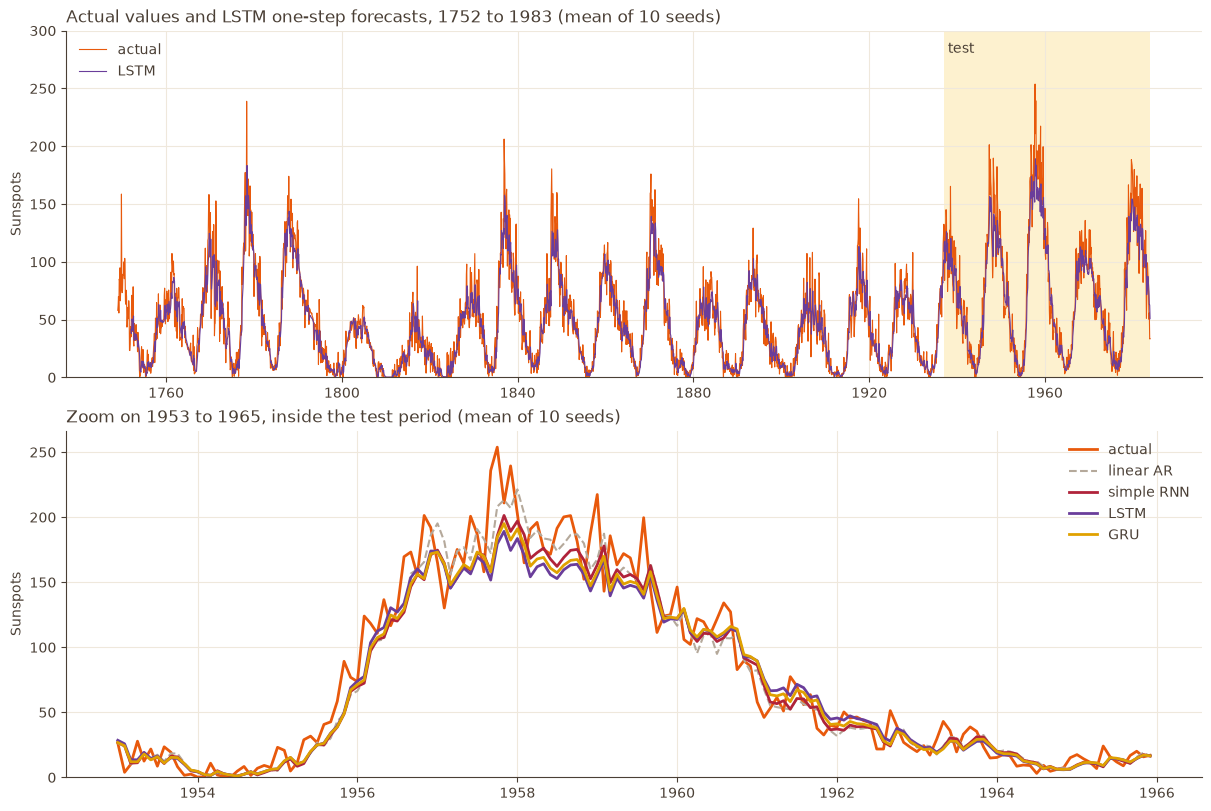

In [9]:
ZOOM: tuple[str, str] = ("1953-01", "1965-12")
test_start = target_dates[1]["test"][0]


def in_sunspots(name: str, part: str) -> np.ndarray:
    # (seeds, windows) in sunspots, from the one-step predictions of every seed.
    return to_sunspots(scaler, network_predictions[1][name][part])[..., 0]


fig, (ax_full, ax_zoom) = plt.subplots(2, 1, figsize=(12, 8), layout="constrained")

ax_full.axvspan(test_start, sunspots.index[-1], color=PALETTE.highlight, linewidth=0)
ax_full.plot(sunspots.index, sunspots, color=PALETTE.color("actual"), linewidth=0.8, label="actual")
for part in ("train", "validation", "test"):
    ax_full.plot(target_dates[1][part], in_sunspots("LSTM", part).mean(axis=0), color=PALETTE.color("LSTM"),
                 linewidth=0.8, label="LSTM" if part == "train" else None)
ax_full.text(test_start, 290, " test", va="top", color=PALETTE.ink)
ax_full.set_ylim(0, 300)
ax_full.set_title("Actual values and LSTM one-step forecasts, 1752 to 1983 (mean of 10 seeds)", loc="left")
ax_full.set_ylabel("Sunspots")
ax_full.legend(loc="upper left", frameon=False)

dates = target_dates[1]["test"]
in_zoom = (dates >= ZOOM[0]) & (dates <= ZOOM[1])
ax_zoom.plot(dates[in_zoom], sunspots[dates[in_zoom]], color=PALETTE.color("actual"), linewidth=2, label="actual")
ax_zoom.plot(dates[in_zoom], to_sunspots(scaler, baseline_predictions[1]["linear AR"]["test"])[in_zoom, 0],
             color=PALETTE.muted, linewidth=1.5, linestyle="--", label="linear AR")
# Thick lines for all three cells, since the gold of the GRU has low contrast on white.
for name in ("simple RNN", "LSTM", "GRU"):
    ax_zoom.plot(dates[in_zoom], in_sunspots(name, "test")[:, in_zoom].mean(axis=0), color=PALETTE.color(name),
                 linewidth=2, label=name)
ax_zoom.set_title("Zoom on 1953 to 1965, inside the test period (mean of 10 seeds)", loc="left")
ax_zoom.set_ylabel("Sunspots")
ax_zoom.set_ylim(bottom=0)
ax_zoom.legend(loc="upper right", frameon=False)

plt.show()

**Findings:**

Over the whole series the LSTM follows the actual values as closely as the simple RNN in notebook 02 and its forecasts are also smoother than the monthly values.

The zoom shows where the gated cells lose on test. Away from the maximum the four forecasts almost overlap. Around the maximum of 1957 to 1959 all of them stay below the actual values, in a clear order: the linear AR model is the highest, then the simple RNN, the GRU and the LSTM, the lowest of all.
The cells that fit validation best are the ones that under-forecast the highest months the most, levels that validation never reached (its maximum is $154.5$, notebook 02, section 7).

## 6. Six steps ahead

The same comparison as in notebook 03, with the gated cells added. 

The recursive strategy reuses the one-step models of section 5 and needs no training. The direct strategy trains new networks with 6 outputs, and since the one-step size turned out to be too small for the direct LSTM on validation, its size is searched again with the same procedure as in section 5.1.

### 6.1 Recursive strategy

In [10]:
for name in gated_builders:
    network_predictions[6][f"{name} recursive"] = {
        part: np.stack([predict_recursive(runs[(name, gated_hidden[name], seed)], X, 6) for seed in SEEDS])
        for part, (X, _) in windows[6].items()
    }

### 6.2 Direct strategy

In section 5 the tied sizes led to 16 units for both cells. A network with 6 outputs solves a harder task, so I repeat the search for the direct models with the same procedure: 16, 32 and 64 units with 10 seeds each, saved in `models/04_gated_cells/direct/`.

In [11]:
X_val, y_val = windows[6]["validation"]
direct_runs: dict = {}
direct_search: dict = {}
for name, (short_name, build) in gated_builders.items():
    for hidden in CANDIDATE_HIDDEN:
        for seed in SEEDS:
            path = MODELS_DIR / "04_gated_cells" / "direct" / f"{short_name}_h{hidden}_seed{seed}.pt"
            model, history = train_or_load(
                lambda: build(hidden, 6), seed, path, windows[6]["train"], windows[6]["validation"], RETRAIN
            )
            direct_runs[(name, hidden, seed)] = model
            direct_search[(name, hidden, seed)] = {
                "validation RMSE": rmse_sunspots(scaler, y_val, predict(model, X_val)),
                "best epoch": best_epoch(history),
            }

direct_search_results = pd.DataFrame.from_dict(direct_search, orient="index").rename_axis(["model", "hidden", "seed"])
direct_search_results.groupby(level=["model", "hidden"], sort=False).agg(["mean", "std", "sem"]).round(2)

validation RMSE             best epoch             
                        mean   std   sem       mean    std   sem
model hidden                                                    
LSTM  16               16.33  0.19  0.06       50.4  17.42  5.51
      32               16.14  0.15  0.05       62.5  22.21  7.02
      64               16.03  0.15  0.05       46.3   9.35  2.96
GRU   16               15.99  0.10  0.03       68.3  11.21  3.54
      32               16.01  0.08  0.03       35.8   9.81  3.10
      64               15.98  0.06  0.02       25.1   4.65  1.47

**Findings:**

The direct LSTM improves with its size: $16.33$ with 16 units, $16.14$ with 32 and $16.03$ with 64, each gap larger than the sems ($0.05$ and $0.06$), so I use 64 units. With 16 units it was the only network worse on validation than the linear AR model ($16.25$ in section 3). For the direct GRU the three sizes are practically tied ($15.99$, $16.01$ and $15.98$, with sems of $0.02$ and $0.03$), so it keeps 16 units. Both sizes are stored as `LSTM_DIRECT_HIDDEN` and `GRU_DIRECT_HIDDEN` in `src/models.py`.

The recursive LSTM keeps the 16 units of section 5, so for this cell the two strategies differ in size as well as in output, and with 64 units the direct LSTM is the largest network of the comparison (section 4).

In [12]:
direct_hidden: dict = {"LSTM": LSTM_DIRECT_HIDDEN, "GRU": GRU_DIRECT_HIDDEN}
for name in gated_builders:
    network_predictions[6][f"{name} direct"] = {
        part: np.stack([predict(direct_runs[(name, direct_hidden[name], seed)], X) for seed in SEEDS])
        for part, (X, _) in windows[6].items()
    }

### 6.3 Errors

In [13]:
error_table(scaler, windows[6], baseline_predictions[6], network_predictions[6]).round(2)

,validation RMSE,test RMSE,test std over seeds,test sem,validation / persistence,test / persistence
model,,,,,,
persistence,19.43,26.45,NaN,NaN,1.00,1.00
linear AR,16.25,22.25,NaN,NaN,0.84,0.84
simple RNN recursive,16.12,23.61,1.19,0.38,0.83,0.89
simple RNN direct,16.06,22.84,0.45,0.14,0.83,0.86
dense recursive,15.93,22.42,1.07,0.34,0.82,0.85
dense direct,15.87,21.39,0.34,0.11,0.82,0.81
LSTM recursive,16.01,24.36,1.55,0.49,0.82,0.92
GRU recursive,15.91,23.54,0.97,0.31,0.82,0.89
LSTM direct,16.03,24.11,0.53,0.17,0.82,0.91


**Findings:**

The gated cells do not help 6 months ahead either. With both strategies they stay above the linear AR model on test ($22.25$): the GRU reaches $23.54$ recursive and $23.34$ direct, and the LSTM $24.36$ and $24.11$. The direct dense network is still the best model ($21.39$), as in notebook 03. On validation all the networks are again close, between $15.87$ and $16.12$, so validation does not separate them.

For the simple RNN and the dense network the direct strategy was better than the recursive one (notebook 03), but for the gated cells the two strategies are practically tied on test: $23.34$ against $23.54$ for the GRU and $24.11$ against $24.36$ for the LSTM, gaps smaller than their sems. The recursive gated models are also the least consistent over seeds, with standard deviations of $0.97$ and $1.55$.

### 6.4 Error at each step ahead

In [14]:
y_test = windows[6]["test"][1]
step_errors = pd.DataFrame(
    {name: step_rmse(scaler, y_test, preds["test"]) for name, preds in baseline_predictions[6].items()}
    | {name: np.mean([step_rmse(scaler, y_test, seed_prediction) for seed_prediction in preds["test"]], axis=0)
       for name, preds in network_predictions[6].items()},
    index=pd.Index(range(1, 7), name="step ahead"),
)
step_errors.T.round(2)

step ahead,1,2,3,4,5,6
persistence,20.13,24.49,26.02,27.52,29.31,31.23
linear AR,18.35,20.94,22.05,23.08,24.06,24.98
simple RNN recursive,18.89,21.91,23.36,24.63,25.85,27.05
simple RNN direct,19.56,21.84,22.80,23.65,24.22,24.99
dense recursive,18.69,21.11,22.19,23.20,24.21,25.10
dense direct,18.67,20.64,21.24,21.92,22.73,23.14
LSTM recursive,19.48,22.83,24.30,25.46,26.56,27.55
GRU recursive,19.01,22.02,23.38,24.51,25.64,26.65
LSTM direct,22.05,23.23,24.23,24.23,25.25,25.69
GRU direct,20.76,22.16,23.10,24.18,24.45,25.42


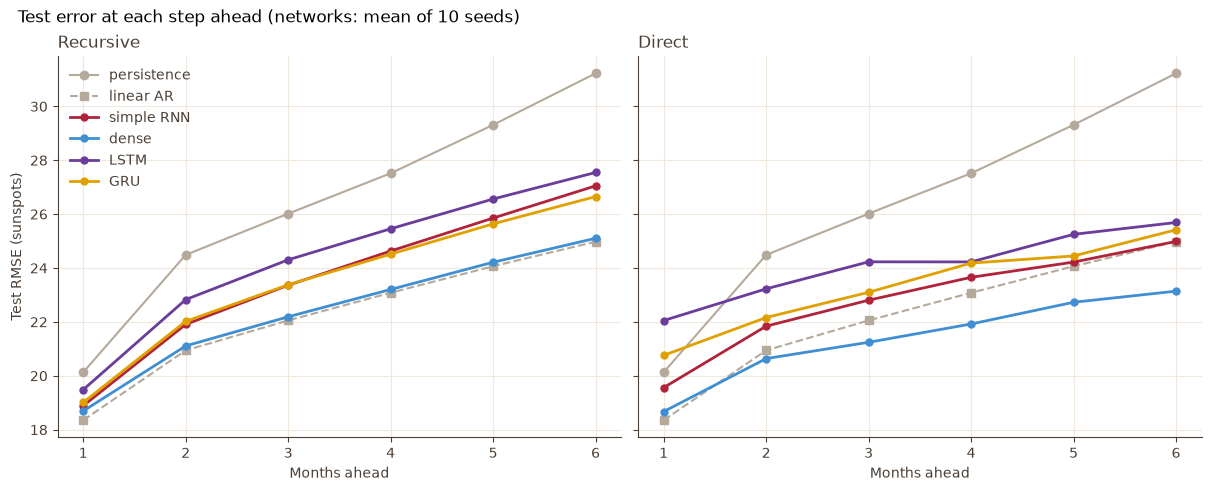

In [15]:
steps = step_errors.index
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True, layout="constrained")

# One panel per strategy, so each network keeps its color and the panels stay readable.
for ax, strategy in zip(axes, ("recursive", "direct")):
    ax.plot(steps, step_errors["persistence"], color=PALETTE.muted, linewidth=1.5, marker="o", label="persistence")
    ax.plot(steps, step_errors["linear AR"], color=PALETTE.muted, linewidth=1.5, linestyle="--", marker="s",
            label="linear AR")
    for name in ("simple RNN", "dense", "LSTM", "GRU"):
        ax.plot(steps, step_errors[f"{name} {strategy}"], color=PALETTE.color(name), linewidth=2,
                marker="o", markersize=5, label=name)
    ax.set_title(strategy.capitalize(), loc="left")
    ax.set_xticks(steps)
    ax.set_xlabel("Months ahead")

axes[0].set_ylabel("Test RMSE (sunspots)")
axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("Test error at each step ahead (networks: mean of 10 seeds)", x=0.01, ha="left")

plt.show()

**Findings:**

In the recursive panel the gated cells follow the simple RNN: one month ahead they start close to it ($19.48$ for the LSTM and $19.01$ for the GRU, against $18.89$) and their error grows at a similar pace, up to $27.55$ and $26.65$ at 6 months. The dense network and the linear AR model stay below all three recurrent cells.

In the direct panel the gated cells start much higher. One month ahead the direct LSTM ($22.05$) is even worse than persistence ($20.13$), and the direct GRU reaches $20.76$. Their error grows more slowly afterwards, so at 6 months they end close to the direct simple RNN ($25.69$ and $25.42$ against $24.99$). The direct gated models lose their ground in the first months, which is why they do not beat their recursive versions on average.

## 7. Window use and hidden states

To explain the errors of sections 5 and 6, this section looks at the one-step models of the four networks: how much each one relies on each part of the window (section 7.1), and the hidden state of the three recurrent cells at the end of the window (section 7.2).

### 7.1 Months used by each network

I use **permutation importance**: shuffle part of the input across the test windows, keep the trained model as it is, and measure how much the test RMSE grows. The larger increase, the more the model relies on that part.
Neighbouring months are strongly correlated (the PACF at lag 1 is $0.922$ in notebook 01, section 4.3), so shuffling a single month would leave its neighbours with almost the same information and every month would look unimportant.     
I therefore shuffle blocks of 6 consecutive months together, from the oldest block (months 1 to 6) to the last one before the target (months 31 to 36), with 5 repeats and the same shuffles for every network.

In [16]:
BLOCK: int = 6
REPEATS: int = 5

X_test, y_test = windows[1]["test"]
# The same shuffle for every network, so the differences come from the models.
rng = np.random.default_rng(0)
permutations = [rng.permutation(len(X_test)) for _ in range(REPEATS)]
blocks = [slice(start, start + BLOCK) for start in range(0, WINDOW, BLOCK)]


def block_importance(model: torch.nn.Module) -> np.ndarray:
    # Increase of the test RMSE when one block of months is shuffled across the windows,
    # averaged over the repeats: one value per block
    base = rmse_sunspots(scaler, y_test, predict(model, X_test))
    increases = np.zeros((len(blocks), REPEATS))
    for b, block in enumerate(blocks):
        for r, permutation in enumerate(permutations):
            shuffled = X_test.copy()
            shuffled[:, block, :] = X_test[permutation, block, :]
            increases[b, r] = rmse_sunspots(scaler, y_test, predict(model, shuffled)) - base
    return increases.mean(axis=1)


cell_models: dict = one_step_models | {
    name: [runs[(name, gated_hidden[name], seed)] for seed in SEEDS] for name in gated_builders
}
importance_table = pd.DataFrame(
    {name: np.mean([block_importance(model) for model in models], axis=0)
     for name, models in cell_models.items()},
    index=[f"{block.start + 1}-{block.stop}" for block in blocks],
).rename_axis("months of the window")
importance_table.T.round(2)

months of the window,1-6,7-12,13-18,19-24,25-30,31-36
simple RNN,0.08,0.46,0.60,0.12,3.48,49.61
dense,1.02,0.68,1.06,0.76,5.65,48.84
LSTM,0.34,0.93,0.98,1.07,4.59,44.58
GRU,0.87,0.72,0.58,0.67,3.47,46.34


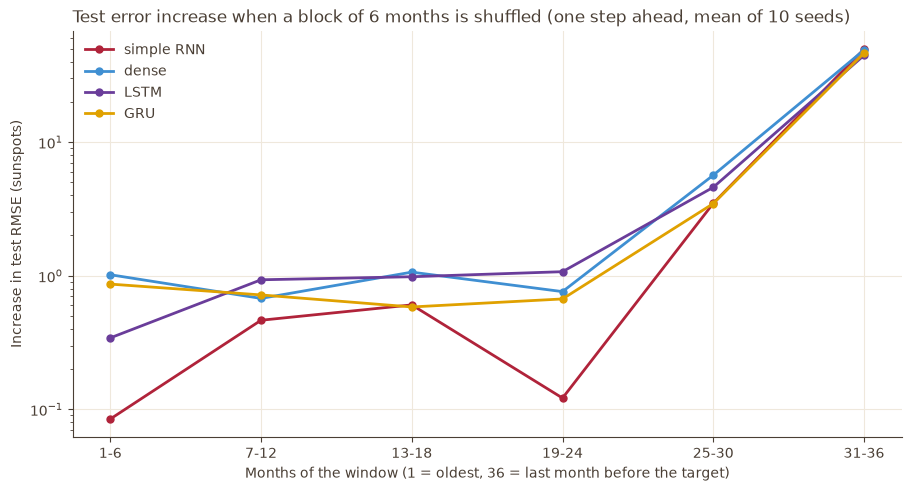

In [17]:
x = np.arange(len(blocks))
fig, ax = plt.subplots(figsize=(9, 4.8), layout="constrained")
for name in cell_models:
    ax.plot(x, importance_table[name], color=PALETTE.color(name), linewidth=2, marker="o", markersize=5, label=name)
# Log scale: the last block is about 50 times larger than the others.
ax.set_yscale("log")
ax.set_xticks(x, importance_table.index)
ax.set_xlabel("Months of the window (1 = oldest, 36 = last month before the target)")
ax.set_ylabel("Increase in test RMSE (sunspots)")
ax.set_title("Test error increase when a block of 6 months is shuffled (one step ahead, mean of 10 seeds)", loc="left")
ax.legend(frameon=False, loc="upper left")

plt.show()

**Findings:**

For every network almost all of the increase comes from the last 6 months of the window: shuffling months 31 to 36 adds between $44.58$ (LSTM) and $49.61$ (simple RNN) to the test RMSE, while each of the four oldest blocks adds about 1 or less. This matches the PACF of notebook 01, section 4.3.

The older months are where the networks differ. The simple RNN barely uses them: shuffling months 1 to 6 adds $0.08$ and months 19 to 24 adds $0.12$.
The LSTM and the GRU spread their reliance further back, closer to the dense network, which sees all months at once: $0.34$ and $0.87$ for the oldest block, and $1.07$ and $0.67$ for months 19 to 24. They also depend a little less on the last block.
The gates do keep information from earlier months, but those months say little about the next one, so the error does not go down (section 5.2).

### 7.2 Hidden states

At the end of a window, a recurrent cell summarizes the 36 months in its last hidden state (16 or 32 numbers here), which is all the linear head sees.
I project these states onto their first two principal components with PCA, for one seed of each cell, and colour each test window by whether the cycle is rising or falling at its target month. The phase comes from a centered 13-month moving average, which looks at future months, so it is only a label for the plot and no model sees it.

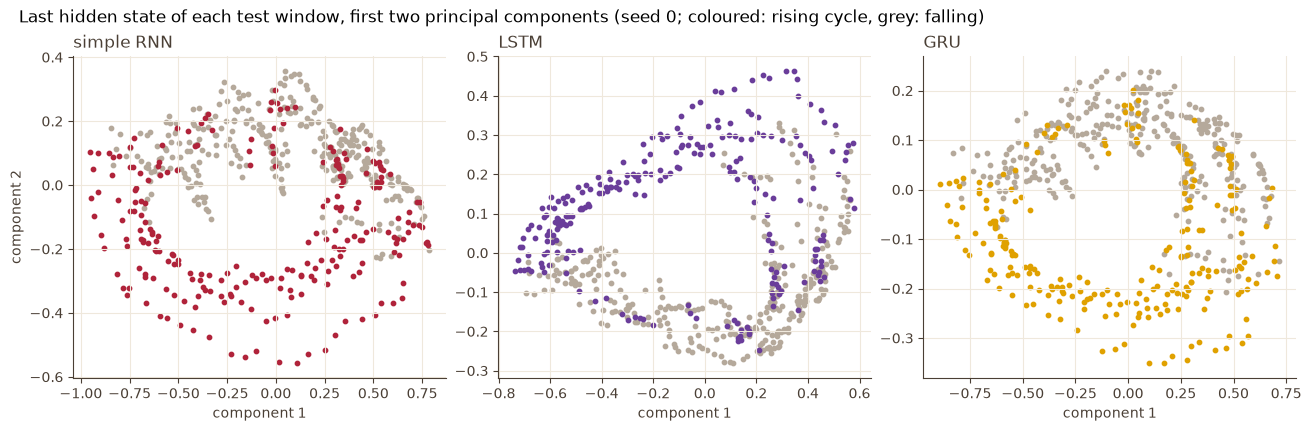

,variance of 2 components,corr. of component 1 with level
simple RNN,0.989,0.900
LSTM,0.953,0.832
GRU,0.995,0.902


In [18]:
# Rising or falling cycle at the target month of each test window.
smooth = sunspots.rolling(13, center=True).mean()
dates = target_dates[1]["test"]
rising = (smooth.diff()[dates] > 0).to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), layout="constrained")
pca_summary: dict = {}
for ax, name in zip(axes, ("simple RNN", "LSTM", "GRU")):
    model = cell_models[name][0]
    model.eval()
    with torch.no_grad():
        states = model.last_hidden(to_tensor(X_test)).numpy()
    pca = PCA(n_components=2).fit(states)
    components = pca.transform(states)
    pca_summary[name] = {
        "variance of 2 components": pca.explained_variance_ratio_.sum(),
        "corr. of component 1 with level": abs(np.corrcoef(components[:, 0], sunspots[dates])[0, 1]),
    }
    ax.scatter(*components[~rising].T, s=10, color=PALETTE.muted)
    ax.scatter(*components[rising].T, s=10, color=PALETTE.color(name))
    ax.set_title(name, loc="left")
    ax.set_xlabel("component 1")
axes[0].set_ylabel("component 2")
fig.suptitle("Last hidden state of each test window, first two principal components "
             "(seed 0; coloured: rising cycle, grey: falling)", x=0.01, ha="left")

plt.show()
pd.DataFrame(pca_summary).T.round(3)

**Findings:**

For the three cells the last hidden state is almost two-dimensional: the first two components explain $0.989$ of its variance for the simple RNN, $0.953$ for the LSTM and $0.995$ for the GRU. The states form a ring.
The first component follows the level of the series (correlation $0.900$, $0.832$ and $0.902$), and the second separates the months where the cycle is rising from those where it is falling, so a network moves around the ring as the cycle advances.

The three cells end with the same summary of the window: the current level and the phase of the cycle. The gates let the LSTM and the GRU read further back (section 7.1), but what they keep is the same two quantities that the simple RNN already builds, which is consistent with the three cells reaching similar errors. These are the states of a single seed per cell.

## 8. Summary

The sizes chosen in this notebook, stored in `src/models.py`:

- **One step ahead:** 16 hidden units for both the LSTM and the GRU, since the three candidate sizes were practically tied on validation (section 5.1). With 16 units both cells are close in size to the simple RNN.

- **Direct, 6 steps ahead:** 64 units for the LSTM, which kept improving with its size, and 16 for the GRU (section 6.2). The recursive forecasts use the one-step models.

What the gated cells change:

- **One step ahead:** the LSTM and the GRU are the best models on validation ($13.56$ and $13.54$), but on test both stay above the linear AR model ($18.32$). The GRU ($19.00$) is practically tied with the simple RNN ($18.85$), and the LSTM ($19.48$) has the highest error of the four networks (section 5.2). Around the maximum of 1957 they under-forecast the highest month the most (section 5.3).

- **Six step ahead:** with both strategies the gated cells stay above the linear AR model ($22.25$): $23.54$ and $23.34$ for the GRU, $24.36$ and $24.11$ for the LSTM. For these cells the recursive and the direct strategy are almost equal and the direct dense network remains the best model ($21.39$, section 6.3).

- **Window use and hidden stats:** the gated cells rely more on the older months of the window than the simple RNN (shuffling months 1 to 6 adds $0.34$ for the LSTM and $0.87$ for the GRU against $0.08$; section 7.1), but the three cells end with the same two-dimensional summary of the window, the level and the phase of the cycle (section 7.2).

Across the four notebooks, the best model one month ahead is the linear AR model ($18.32$) and six months ahead the direct dense network ($21.39$). The networks fit validation well but forecast the high levels of the test period too low, levels that are rare in the training data (notebook 02, section 7) and none of the recurrent cells change that.